In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from time import time

# Import all models
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasRegressor

# Import all tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Set warnings to ignore
warnings.filterwarnings('ignore')
print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# --- 1. Load Data ---
# Use the v3 dataset that includes the HOMO-LUMO Gap
df = pd.read_csv("../../data/thesis/final_model_dataset_v3.csv")
print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.")

# --- 2. Define Features (X) and Target (y) ---
ignore_cols = ["cation", "cation_ion_name", "anion", "anion_ion_name"]
target_col = "CO2_solubility"
feature_cols = [col for col in df.columns if col not in ignore_cols + [target_col]]
X = df[feature_cols]
y = df[target_col].values

# --- 3. Split Data ---
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# --- 4. Scale Data ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"Data preparation complete. Training on {len(X_train)} samples, validating on {len(X_val)} samples.")

Dataset loaded with 11256 rows and 253 columns.
Data preparation complete. Training on 9004 samples, validating on 2252 samples.


In [3]:
# --- Model 1: Neural Network (requires a create function for the wrapper) ---
def create_model(meta):
    n_features_in_ = meta["n_features_in_"]
    model = keras.Sequential([
        layers.Input(shape=(n_features_in_,)),
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)
    ])
    # Compile with 'mae' metric so we can get the MAE score
    model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])
    return model

# --- Create a dictionary of all models to train ---
models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Neural Network": KerasRegressor(
        model=create_model,
        epochs=100,
        batch_size=32,
        verbose=0,
        validation_split=0.2 # Use 20% of training data for validation curves
    )
}

print(f"Initialized {len(models)} models.")

Initialized 4 models.


In [4]:
# This cell will run all models and collect their metrics
results = {}
histories = {} # To store the NN training history

print("--- Starting Model Training & Evaluation ---")

for name, model in models.items():
    print(f"\nTraining {name}...")
    start_time = time()
    
    # Train the model
    # For the NN, we pass the validation_data to get the history
    if name == "Neural Network":
        history = model.fit(X_train_scaled, y_train)
        histories[name] = history.history_
    else:
        model.fit(X_train_scaled, y_train)
    
    # Make predictions
    y_pred = model.predict(X_val_scaled)
    if hasattr(y_pred, 'flatten'):
        y_pred = y_pred.flatten()
            
    # Calculate metrics
    r2 = r2_score(y_val, y_pred)
    mae = mean_absolute_error(y_val, y_pred)
    rmse = root_mean_squared_error(y_val, y_pred)
    train_time = time() - start_time
    
    # Store results
    results[name] = {"R²": r2, "MAE": mae, "RMSE": rmse, "Time (s)": train_time}
    
    print(f"  > Done in {train_time:.2f}s")

print("\n--- All models trained and evaluated. ---")

--- Starting Model Training & Evaluation ---

Training Ridge Regression...
  > Done in 0.04s

Training Random Forest...
  > Done in 0.87s

Training Gradient Boosting...
  > Done in 1.14s

Training Neural Network...
  > Done in 21.80s

--- All models trained and evaluated. ---


In [6]:
# Convert results to a DataFrame for easy printing
results_df = pd.DataFrame(results).T
results_df = results_df[['R²', 'MAE', 'RMSE', 'Time (s)']] # Set column order

print("\n--- Point 1: Model Performance Metrics (on Test Set) ---")
print(results_df.to_markdown(floatfmt=".4f"))


--- Point 1: Model Performance Metrics (on Test Set) ---
|                   |     R² |    MAE |   RMSE |   Time (s) |
|:------------------|-------:|-------:|-------:|-----------:|
| Ridge Regression  | 0.5906 | 0.1164 | 0.1455 |     0.0448 |
| Random Forest     | 0.9853 | 0.0167 | 0.0275 |     0.8704 |
| Gradient Boosting | 0.9729 | 0.0257 | 0.0374 |     1.1357 |
| Neural Network    | 0.9616 | 0.0360 | 0.0445 |    21.8047 |



--- Point 2: Training vs. Validation Performance (Overfitting Analysis) ---


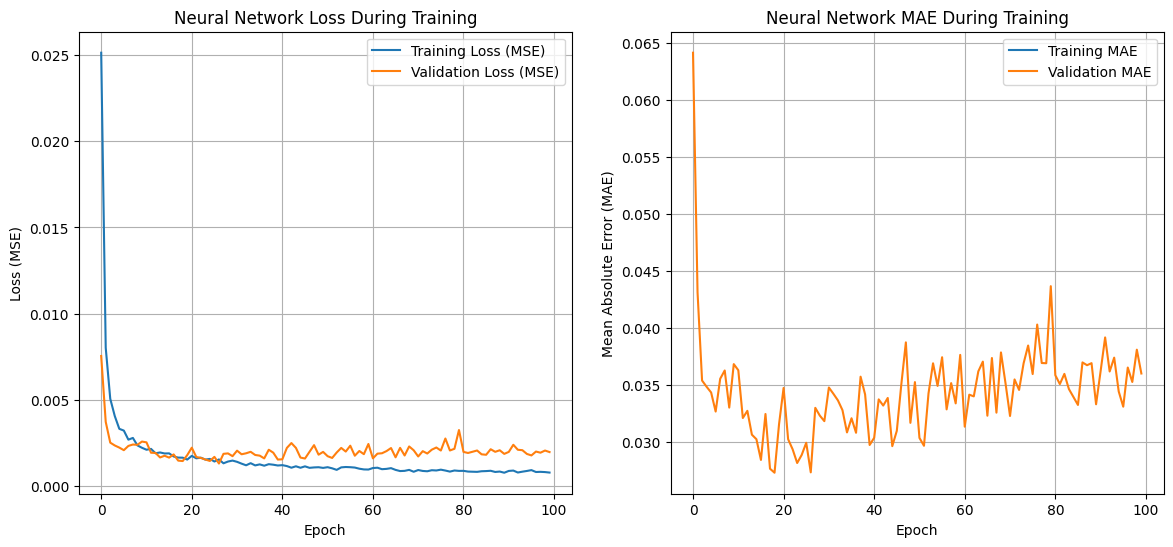


Analysis of Overfitting:
The plots above show the model's error (Loss and MAE) on the training data vs. the unseen validation data at each epoch.
If the lines track each other closely (both go down and then flatten out), the model is generalizing well.
If the validation loss/MAE starts to *increase* while the training loss/MAE continues to decrease, it is a sign of overfitting.

Note on Cross-Validation:
This analysis used a single 80/20 train-test split. K-Fold cross-validation (e.g., 5-fold or 10-fold) was not performed.
However, given the large size of the dataset (11,000+ points), the 20% test set (2,200+ points) is very large and provides a statistically robust evaluation of the model's performance.


In [7]:
print("\n--- Point 2: Training vs. Validation Performance (Overfitting Analysis) ---")

# Plot the NN history
nn_history = histories["Neural Network"]
plt.figure(figsize=(14, 6))

# Plot training & validation loss (MSE)
plt.subplot(1, 2, 1)
plt.plot(nn_history['loss'], label='Training Loss (MSE)')
plt.plot(nn_history['val_loss'], label='Validation Loss (MSE)')
plt.title('Neural Network Loss During Training')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

# Plot training & validation MAE
plt.subplot(1, 2, 2)
plt.plot(nn_history['mae'], label='Training MAE')
plt.plot(nn_history['val_mae'], label='Validation MAE')
plt.title('Neural Network MAE During Training')
plt.xlabel('Epoch')
plt.ylabel('Mean Absolute Error (MAE)')
plt.legend()
plt.grid(True)

plt.show()

print("\nAnalysis of Overfitting:")
print("The plots above show the model's error (Loss and MAE) on the training data vs. the unseen validation data at each epoch.")
print("If the lines track each other closely (both go down and then flatten out), the model is generalizing well.")
print("If the validation loss/MAE starts to *increase* while the training loss/MAE continues to decrease, it is a sign of overfitting.")

print("\nNote on Cross-Validation:")
print("This analysis used a single 80/20 train-test split. K-Fold cross-validation (e.g., 5-fold or 10-fold) was not performed.")
print("However, given the large size of the dataset (11,000+ points), the 20% test set (2,200+ points) is very large and provides a statistically robust evaluation of the model's performance.")